# 05c — Why does the model colonise the west too slowly?

Notebook 05b showed that, west of the 2015 front, **58 cells** got their first toad record by 2025, while the colonisation model expected **about 11**. The position of the front looked right only because a few simulated jumps into the desert pushed it west.

This notebook looks for the cause and tests fixes. Three hypotheses:

1. **The rate changed over space or time.** The model has one set of coefficients for all of Australia and all years, and it learned mostly from Queensland, where the invasion is old and slow. The invasion front in the Northern Territory was much faster: toads at the front evolved to disperse faster (Phillips et al. 2006), and spread rates vary across the range (Urban et al. 2008).
2. **Survey effort.** Many more frogs were recorded after 2017 (FrogID), so cells got their *first record* faster, without more toads.
3. **Training period.** Training up to 2020 instead of 2015 lets the model see part of the fast western front and the high-effort years.

Every fix is judged on the same backtest as notebook 05, plus a backtest trained up to 2020 and tested on 2021–2025. The key new metric is the number of new cells **west of the front at the cut-off year**, observed vs simulated.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from scipy.spatial import cKDTree
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from colonization import FEATURES, cell_year_table, simulate
from environment import BIOCLIM_VARIABLES, environmental_grid
from front import AUSTRALIAN_ALBERS, records_to_cells

PROCESSED = PROJECT_ROOT / "data" / "processed"
RAW = PROJECT_ROOT / "data" / "raw"
FIGURES = PROJECT_ROOT / "figures"
CELL_SIZE_M = 25_000
CLIMATE = list(BIOCLIM_VARIABLES.values())
TRAIN_START = 1990
N_RUNS = 50

cells = environmental_grid(CELL_SIZE_M)
first_detection = records_to_cells(
    pd.read_csv(PROCESSED / "rhinella_marina_clean.csv"), CELL_SIZE_M
)[["cx", "cy", "first_year"]]
cells = cells.merge(first_detection, how="left", on=["cx", "cy"])
cells["first_year"] = cells["first_year"].fillna(np.inf)
cells["x_km"] = (cells["cx"] + 0.5) * CELL_SIZE_M / 1000
cells["y_km"] = (cells["cy"] + 0.5) * CELL_SIZE_M / 1000
cells["region"] = np.select([cells["lon"] >= 138, cells["lon"] >= 129], ["Queensland", "Northern Territory"],
                            default="Western Australia")
x_km = cells["x_km"].to_numpy()
west = (cells["lon"] < 141).to_numpy()
first_year = cells["first_year"].to_numpy()
print(cells["region"].value_counts().to_string())

region
Queensland            5057
Western Australia     4044
Northern Territory    3211


## 1. Is the rate the same everywhere? Calibration by region and period

The main model of notebook 05 (trained 1990–2015) predicts, for every cell at risk and year, the probability of being colonised **given the true occupancy of the previous year** (one step ahead). Summing those probabilities gives the expected number of colonisations, which we compare with the observed number by region and period. Ratio < 1 means the model is too slow there.

In [2]:
def climate_model():
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000))


def suitability(cutoff_year: int) -> np.ndarray:
    training = cells[CLIMATE].assign(toad=(cells["first_year"] <= cutoff_year).astype(int))
    return climate_model().fit(training[CLIMATE], training["toad"]).predict_proba(cells[CLIMATE])[:, 1]


def logistic():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))


suitability_2015 = suitability(2015)
table = cell_year_table(cells, suitability_2015, range(TRAIN_START, 2026))
table["region"] = cells["region"].to_numpy()[table["cell"]]
table["period"] = pd.cut(table["year"], [1989, 2004, 2015, 2025], labels=["1990-2004", "2005-2015", "2016-2025 (test)"])
main = logistic().fit(table.loc[table["year"] <= 2015, FEATURES], table.loc[table["year"] <= 2015, "colonised"])
table["expected"] = main.predict_proba(table[FEATURES])[:, 1]

calibration = table.groupby(["region", "period"], observed=True)[["colonised", "expected"]].sum()
calibration["observed / expected"] = calibration["colonised"] / calibration["expected"]
calibration.round(2)

colonised  expected  observed / expected
region             period                                                    
Northern Territory 1990-2004                56     43.47                 1.29
                   2005-2015               130     53.03                 2.45
                   2016-2025 (test)        105     47.01                 2.23
Queensland         1990-2004               168    223.48                 0.75
                   2005-2015                92    146.11                 0.63
                   2016-2025 (test)        136    122.70                 1.11
Western Australia  1990-2004                 0      6.21                 0.00
                   2005-2015                21      9.07                 2.32
                   2016-2025 (test)         72     17.98                 4.00

## 2. Survey effort: records of other frogs

Records of all other amphibians per cell and year are a proxy for how much people looked (the same target-group idea as notebook 03).

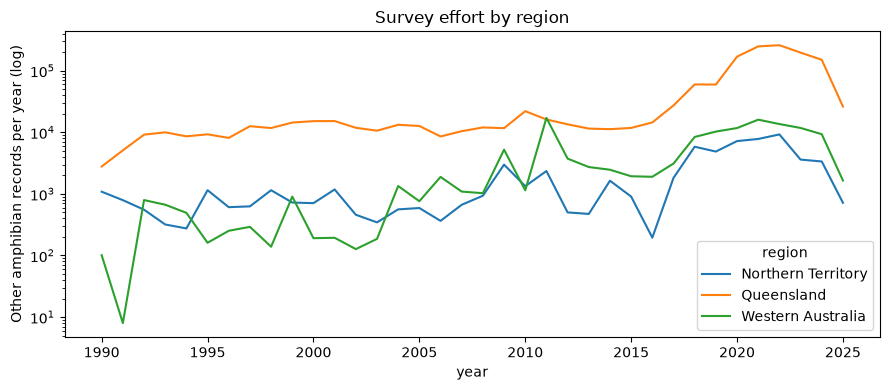

In [3]:
amphibians = pd.read_csv(RAW / "amphibia_ala.csv", low_memory=False)
others = amphibians.loc[
    (amphibians["scientificName"] != "Rhinella marina")
    & amphibians["decimalLatitude"].notna() & amphibians["year"].notna()
    & ~(amphibians["coordinateUncertaintyInMeters"] > 10_000)
]
points = gpd.GeoSeries(gpd.points_from_xy(others["decimalLongitude"], others["decimalLatitude"]), crs=4326).to_crs(AUSTRALIAN_ALBERS)
effort = (
    pd.DataFrame({"cx": (points.x // CELL_SIZE_M).astype(int).to_numpy(),
                  "cy": (points.y // CELL_SIZE_M).astype(int).to_numpy(),
                  "year": others["year"].astype(int).to_numpy()})
    .value_counts().rename("records").reset_index()
)
cell_index = pd.Series(np.arange(len(cells)), index=pd.MultiIndex.from_frame(cells[["cx", "cy"]]))
effort["cell"] = cell_index.reindex(pd.MultiIndex.from_frame(effort[["cx", "cy"]])).to_numpy()
effort = effort.dropna(subset=["cell"]).astype({"cell": int})
effort_matrix = effort.pivot_table(index="cell", columns="year", values="records", aggfunc="sum").reindex(range(len(cells))).fillna(0)

by_region = effort.assign(region=cells["region"].to_numpy()[effort["cell"]]).pivot_table(
    index="year", columns="region", values="records", aggfunc="sum").loc[1990:2025]
ax = by_region.plot(figsize=(9, 4), logy=True)
ax.set(ylabel="Other amphibian records per year (log)", title="Survey effort by region")
plt.tight_layout()
plt.savefig(FIGURES / "05c_effort_by_region.png", dpi=150)

In [4]:
effort_years = effort_matrix.columns.to_numpy().astype(int)
effort_values = effort_matrix.to_numpy()


def log_effort(cell_ids: np.ndarray, years: np.ndarray) -> np.ndarray:
    column = np.clip(np.searchsorted(effort_years, years), 0, len(effort_years) - 1)
    known = effort_years[column] == years
    records = np.where(known, effort_values[cell_ids, column], 0)
    return np.log1p(records)


table["log_effort"] = log_effort(table["cell"].to_numpy(), table["year"].to_numpy())
rate = table.assign(any_effort=table["log_effort"] > 0).groupby(["period", "any_effort"], observed=True)["colonised"].mean() * 1000
rate.rename("colonisations per 1,000 cell-years").round(2).unstack()

any_effort,False,True
period,,
1990-2004,0.24,22.15
2005-2015,0.56,27.01
2016-2025 (test),1.03,16.89


## 3. Fixes tested in the backtest

| Variant | What changes |
|---|---|
| Main (notebook 05) | Distance, neighbours and suitability; trained on all years since 1990 |
| Recent window | Trained only on the last 10 years before the cut-off, so old Queensland years weigh less |
| Region-specific | Adds an indicator for cells outside Queensland and its interaction with distance and neighbours |
| Effort | Adds the log number of other-amphibian records in the cell and year. In the simulation it uses the effort actually recorded in each test year: this tests whether effort explains the gap, but a real forecast would need an assumption about future effort |
| Effort near the range | The same, but effort only counts within 100 km of an occupied cell. Far from any toad, more frog surveys cannot reveal a toad, so effort there should not raise the probability |

Each variant is evaluated with two cut-offs: trained up to 2015 and simulated to 2025 (as in notebook 05), and trained up to 2020 and simulated to 2025.

In [5]:
outside_queensland = (cells["region"] != "Queensland").astype(int).to_numpy()


def region_features(cell_ids, base: pd.DataFrame) -> pd.DataFrame:
    flag = outside_queensland[cell_ids]
    return pd.DataFrame({
        "outside_queensland": flag,
        "outside_x_log_distance": flag * base["log_distance_km"].to_numpy(),
        "outside_x_neighbours_50km": flag * base["neighbours_50km"].to_numpy(),
    }, index=base.index)


def effort_in(year: int) -> np.ndarray:
    return log_effort(np.arange(len(cells)), np.full(len(cells), year))


REGION = ["outside_queensland", "outside_x_log_distance", "outside_x_neighbours_50km"]
VARIANTS = {
    "main (notebook 05)": {"features": FEATURES, "window": None},
    "recent window (10 years)": {"features": FEATURES, "window": 10},
    "region-specific": {"features": FEATURES + REGION, "window": None},
    "effort": {"features": FEATURES + ["log_effort"], "window": None},
    "region-specific + effort": {"features": FEATURES + REGION + ["log_effort"], "window": None},
    "effort near the range": {"features": FEATURES + ["log_effort_near"], "window": None},
    "region-specific + effort near the range": {"features": FEATURES + REGION + ["log_effort_near"], "window": None},
}
NEAR_KM = 100
EFFORT = ["log_effort", "log_effort_near"]


def effort_near(frame: pd.DataFrame) -> np.ndarray:
    '''Survey effort counts only within NEAR_KM of an occupied cell: records far from any toad cannot reveal one.'''
    return frame["log_effort"].to_numpy() * (np.expm1(frame["log_distance_km"].to_numpy()) <= NEAR_KM)


def western_front(occupied: np.ndarray) -> float:
    return np.sort(x_km[occupied & west])[2]


def add_extra(frame: pd.DataFrame, features) -> pd.DataFrame:
    if any(f in REGION for f in features):
        frame = frame.join(region_features(frame["cell"].to_numpy(), frame))
    if any(f in EFFORT for f in features):
        frame["log_effort"] = log_effort(frame["cell"].to_numpy(), frame["year"].to_numpy())
    if "log_effort_near" in features:
        frame["log_effort_near"] = effort_near(frame)
    return frame

The region interactions depend on the distance and neighbour features, which change during the simulation, so the simulation needs them recomputed every year. The cleanest way is a small wrapper model that adds them just before predicting.

In [6]:
class WithRegion:
    """Adds the region terms and near-range effort before calling the fitted pipeline."""

    def __init__(self, pipeline, features):
        self.pipeline, self.features = pipeline, features

    def predict_proba(self, frame: pd.DataFrame):
        frame = frame.copy()
        if "outside_queensland" in self.features:
            frame = frame.join(region_features(frame.index.to_numpy(), frame))
        if "log_effort_near" in self.features:
            frame["log_effort_near"] = effort_near(frame)
        return self.pipeline.predict_proba(frame[self.features])


desert = (cells["climate_zone"] == "Desert (BW)").to_numpy()
FAR_KM = 300


def frozen_effort(cutoff: int) -> np.ndarray:
    '''What a forecaster knows at the cut-off: mean records per cell in the last 3 years.'''
    columns = [y for y in range(cutoff - 2, cutoff + 1) if y in effort_matrix.columns]
    return np.log1p(effort_matrix[columns].mean(axis=1).to_numpy())


def run(name: str, cutoff: int, years, effort_mode: str = "observed", desert_mask: bool = False,
        n_runs: int = N_RUNS, seed: int = 0) -> np.ndarray:
    '''Fit a variant with data up to `cutoff` and simulate the following `years`.'''
    spec = VARIANTS[name]
    features = spec["features"]
    score = suitability(cutoff)
    start = TRAIN_START if spec["window"] is None else cutoff - spec["window"] + 1
    train = add_extra(cell_year_table(cells, score, range(start, cutoff + 1)), features)
    model = WithRegion(logistic().fit(train[features], train["colonised"]), features)
    needs_effort = any(f in EFFORT for f in features)
    base_features = FEATURES + (["log_effort"] if needs_effort else [])
    extra = None
    if needs_effort:
        frozen = frozen_effort(cutoff)
        extra = (lambda year: pd.DataFrame({"log_effort": effort_in(year)})) if effort_mode == "observed" \
            else (lambda year: pd.DataFrame({"log_effort": frozen}))
    sim_score = np.where(desert, 0.0, score) if desert_mask else score
    return simulate(model, cells, sim_score, cutoff, years, n_runs=n_runs, features=base_features,
                    extra_features=extra, seed=seed)


def evaluate(simulated: np.ndarray, cutoff: int, end: int = 2025) -> dict:
    occupied = simulated <= end
    occupied_cutoff = first_year <= cutoff
    observed_end = first_year <= end
    new = ~occupied_cutoff
    beyond = west & (x_km < western_front(occupied_cutoff)) & new
    distance_to_range, _ = cKDTree(cells.loc[occupied_cutoff, ["x_km", "y_km"]].to_numpy()).query(cells[["x_km", "y_km"]].to_numpy())
    far = new & (distance_to_range > FAR_KM)
    p = np.clip(occupied.mean(axis=0)[new], 1e-3, 1 - 1e-3)
    y = observed_end[new].astype(float)
    fronts = np.array([western_front(run) for run in occupied])
    return {
        "multi-step AUC": roc_auc_score(y, p),
        "Brier score": np.mean((p - y) ** 2),
        "log loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
        "new cells: observed": int(y.sum()),
        "new cells: simulated (median)": np.median(occupied[:, new].sum(axis=1)),
        "west of cut-off front: observed": int(observed_end[beyond].sum()),
        "west of cut-off front: simulated (mean)": occupied[:, beyond].sum(axis=1).mean(),
        f"more than {FAR_KM} km from the range: observed": int(observed_end[far].sum()),
        f"more than {FAR_KM} km from the range: simulated (mean)": occupied[:, far].sum(axis=1).mean(),
        "front error (km)": np.median(fronts) - western_front(observed_end),
    }

## 4. Results

Besides the counts, two **proper scoring rules** for probabilistic forecasts (Gneiting & Raftery 2007), computed over the cells empty at the cut-off: the **Brier score** (mean squared difference between the predicted probability and what happened, 0 = perfect) and the **log loss** (punishes confident mistakes). Lower is better for both. The **Brier skill score** compares each variant with the model of notebook 05: positive = better, negative = worse.

`effort (frozen)` is the honest version of the effort variants: instead of the effort actually recorded after the cut-off, which a forecaster cannot know, it uses the mean effort of the last 3 years before the cut-off.

In [7]:
runs, results = {}, {}
CASES = [(name, "observed") for name in VARIANTS] + [("region-specific + effort near the range", "frozen")]
for cutoff in [2015, 2020]:
    for name, effort_mode in CASES:
        label = name if effort_mode == "observed" else f"{name} (frozen effort)"
        runs[(cutoff, label)] = run(name, cutoff, range(cutoff + 1, 2026), effort_mode)
        results[(cutoff, label)] = evaluate(runs[(cutoff, label)], cutoff)
comparison = pd.DataFrame(results).T
comparison.index.names = ["trained up to", "variant"]
reference = comparison.xs("main (notebook 05)", level="variant")["Brier score"]
comparison["Brier skill vs notebook 05"] = 1 - comparison["Brier score"] / comparison.index.get_level_values(0).map(reference)
comparison.round(3)

multi-step AUC  \
trained up to variant                                                              
2015          main (notebook 05)                                           0.829   
              recent window (10 years)                                     0.857   
              region-specific                                              0.851   
              effort                                                       0.864   
              region-specific + effort                                     0.898   
              effort near the range                                        0.854   
              region-specific + effort near the range                      0.894   
              region-specific + effort near the range (frozen...           0.843   
2020          main (notebook 05)                                           0.774   
              recent window (10 years)                                     0.796   
              region-specific                                              0.815   
              effort                                                       0.813   
              region-specific + effort                                     0.865   
              effort near the range                                        0.842   
              region-specific + effort near the range                      0.853   
              region-specific + effort near the range (frozen...           0.824   

                                                                  Brier score  \
trained up to variant                                                           
2015          main (notebook 05)                                        0.025   
              recent window (10 years)                                  0.025   
              region-specific                                           0.025   
              effort                                                    0.028   
              region-specific + effort                                  0.027   
              effort near the range                                     0.027   
              region-specific + effort near the range                   0.025   
              region-specific + effort near the range (frozen...        0.025   
2020          main (notebook 05)                                        0.016   
              recent window (10 years)                                  0.016   
              region-specific                                           0.016   
              effort                                                    0.018   
              region-specific + effort                                  0.017   
              effort near the range                                     0.018   
              region-specific + effort near the range                   0.017   
              region-specific + effort near the range (frozen...        0.018   

                                                                  log loss  \
trained up to variant                                                        
2015          main (notebook 05)                                     0.108   
              recent window (10 years)                               0.102   
              region-specific                                        0.103   
              effort                                                 0.121   
              region-specific + effort                               0.112   
              effort near the range                                  0.122   
              region-specific + effort near the range                0.110   
              region-specific + effort near the range (frozen...     0.110   
2020          main (notebook 05)                                     0.079   
              recent window (10 years)                               0.076   
              region-specific                                        0.074   
              effort                                                 0.083   
  

## 5. Calibration: are the percentages believable?

Cells are grouped by the probability the model gave them; within each group, the share that actually got a toad record by 2025 should match the probability. Points on the diagonal = well calibrated; below = the model is overconfident; above = it is too cautious.

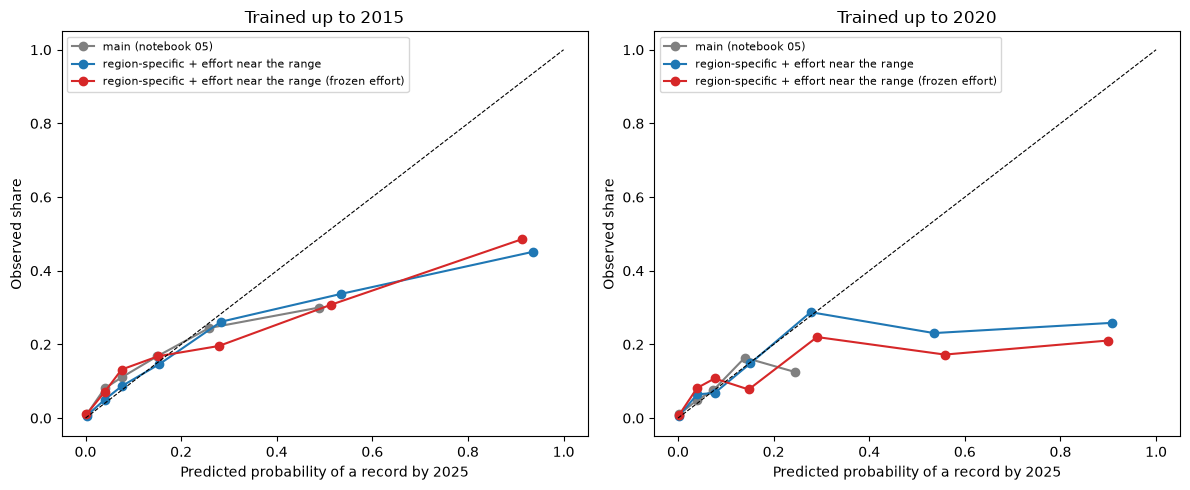

In [8]:
BINS = [0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cutoff in zip(axes, [2015, 2020]):
    new = first_year > cutoff
    for label, colour in [("main (notebook 05)", "grey"), ("region-specific + effort near the range", "tab:blue"),
                          ("region-specific + effort near the range (frozen effort)", "tab:red")]:
        p = (runs[(cutoff, label)] <= 2025).mean(axis=0)[new]
        y = (first_year <= 2025)[new]
        groups = pd.DataFrame({"p": p, "y": y, "bin": pd.cut(p, BINS, include_lowest=True)}).groupby("bin", observed=True)
        table = groups.agg(predicted=("p", "mean"), observed=("y", "mean"), cells=("y", "size"))
        ax.plot(table["predicted"], table["observed"], "o-", color=colour, label=label)
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set(xlabel="Predicted probability of a record by 2025", ylabel="Observed share", title=f"Trained up to {cutoff}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "05c_calibration.png", dpi=150)

## 6. Saving the improved model for the page

The page compares reality with a model trained up to **2020** for 2021–2025, and shows the forecast for 2026–2035 trained up to 2025. For the forecast, effort is frozen at its 2023–2025 mean, so the probabilities answer: *would the toad be recorded if people keep looking as much as they do now?* Both with and without the desert mask (notebook 05b).

In [9]:
BEST = "region-specific + effort near the range"
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2
pilbara = (cells["lon"].between(116, 121) & cells["lat"].between(-23, -19)).to_numpy()
cell_columns = cells[["cx", "cy", "lon", "lat", "first_year"]].reset_index(drop=True)
summaries = []
for desert_mask in [False, True]:
    scenario = "improved model" + (", desert limit" if desert_mask else "")
    name = scenario.replace(", ", "_").replace(" ", "_")
    for period, cutoff, years, n_runs in [("backtest", 2020, range(2021, 2026), N_RUNS), ("forecast", 2025, range(2026, 2036), 200)]:
        simulated = run(BEST, cutoff, years, effort_mode="frozen", desert_mask=desert_mask, n_runs=n_runs, seed=1)
        probability = pd.DataFrame({f"p_{year}": (simulated <= year).mean(axis=0) for year in years})
        pd.concat([cell_columns, probability], axis=1).to_csv(PROCESSED / f"{period}_{name}.csv", index=False)
        for year in years:
            occupied = simulated <= year
            area = occupied.sum(axis=1) * CELL_KM2
            front = np.array([western_front(r) for r in occupied])
            summaries.append({
                "scenario": scenario, "period": period, "year": year,
                "area_median": np.median(area), "area_p5": np.percentile(area, 5), "area_p95": np.percentile(area, 95),
                "front_x_median": np.median(front), "front_x_p5": np.percentile(front, 5), "front_x_p95": np.percentile(front, 95),
                "p_pilbara": occupied[:, pilbara].any(axis=1).mean(),
            })
summary = pd.DataFrame(summaries)
summary.to_csv(PROCESSED / "simulation_summary_by_year_improved.csv", index=False)
summary.loc[summary["year"].isin([2025, 2030, 2035])].round(2)

,scenario,period,year,area_median,area_p5,area_p95,front_x_median,front_x_p5,front_x_p95,p_pilbara
4,improved model,backtest,2025,789375.0,774593.75,799718.75,-737.5,-1065.00,-737.5,0.12
9,improved model,forecast,2030,908125.0,894375.00,920687.50,-887.5,-1188.75,-862.5,0.22
14,improved model,forecast,2035,997500.0,981218.75,1013812.50,-1012.5,-1538.75,-887.5,0.46
19,"improved model, desert limit",backtest,2025,787812.5,775906.25,797843.75,-737.5,-851.25,-737.5,0.06
24,"improved model, desert limit",forecast,2030,903750.0,892500.00,915000.00,-887.5,-988.75,-862.5,0.06
29,"improved model, desert limit",forecast,2035,989687.5,975593.75,1005656.25,-962.5,-1512.50,-887.5,0.16


## Takeaways

- **The model of notebook 05 was too slow in the west because it learned the rate of Queensland.** One step ahead, it expected 2–4 times fewer colonisations than observed in the Northern Territory and Western Australia, already within the training period. Region-specific terms are needed.
- **Survey effort is a huge driver of first records** (20–100 times more first records in cell-years with other frog records), but it has to be handled with care: used everywhere, it creates toads where many people look for frogs, far from any invasion (41 simulated cells more than 300 km from the range, against 7 observed). Restricted to the surroundings of the range, the counts and the front become right: 192 simulated new cells against 187 observed (trained up to 2020), and a front error of 0–37 km (trained up to 2015).
- **But the proper scoring rules do not improve.** The Brier score and log loss are practically the same as notebook 05's, and the calibration curves show why: the effort models are **overconfident at high probabilities** (cells given ~90% got a record only 20–45% of the time). They get the totals right by spreading more probability, not by placing it better cell by cell.
- **Lesson:** counts, front position and AUC can improve while the probabilities themselves do not. This is why proper scoring rules and calibration are needed to judge a probabilistic forecast.
- **Next step (notebook 05d):** separate the two processes behind a record (toads arriving, and people detecting them), which is what the question really needs: the probability that toads are present.